# Text-to-color
Two complementary trainable PyTorch networks (RGB and CIELAB), using real XKCD survey labels. Kornia handles standard color-space conversion; LiteRT converts the actual trained PyTorch ensemble.

In [ ]:
%pip install kornia==0.8.2 litert-torch==0.9.3

# Let pip resolve the converter, interpreter and quantizer together.
# Published LiteRT Torch 0.9.3 dependencies:
#   ai-edge-litert[model-utils]>=2.1.6,<2.2.0
#   ai-edge-quantizer==0.8.*
#   litert-converter==0.3.*
from importlib.metadata import version
from packaging.specifiers import SpecifierSet

expected_versions = {
    "litert-torch": "==0.9.3",
    "ai-edge-litert": ">=2.1.6,<2.2.0",
    "ai-edge-quantizer": "==0.8.*",
    "litert-converter": "==0.3.*",
    "kornia": "==0.8.2",
}
for package, spec in expected_versions.items():
    installed = version(package)
    if installed not in SpecifierSet(spec):
        raise RuntimeError(f"{package} {installed} does not satisfy {spec}. Use a fresh runtime and rerun this cell.")
    print(f"{package}: {installed}")
print("LiteRT dependency versions are compatible with litert-torch 0.9.3.")
print("If pip changed PyTorch or a previously imported package, restart the kernel before continuing.")

INFO: pip is looking at multiple versions of anyio to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 7.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 695.8/695.8 kB 17.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 2.5 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 47.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.8/69.8 MB 3.1 MB/s  0:00:22
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.3/532.3 MB 21.1 MB/s  0:00:21
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 18.4 MB/s  0:00:15
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 36.4 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.0/206.0 MB 24.4 MB/s  0:00:08
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 39.6 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 197.7/197.7 MB 38.1 MB/s  0:00:05
   ━━━━━━━━━━━━━━

In [ ]:
import json
import re
from pathlib import Path

import torch
from torch import nn
from kornia.color import rgb_to_lab, lab_to_rgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import XKCD_COLORS, to_rgb, to_hex
from skimage.color import rgb2lab, deltaE_ciede2000
from IPython.display import display

SEED = 42
OUT = Path("color_v33_results")
OUT.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)

## 1. Text preprocessing

In [ ]:
BASE_COLORS = [
    "red", "orange", "yellow", "green", "blue", "purple",
    "pink", "brown", "gray", "black", "white", "teal",
    "cyan", "turquoise", "lime", "olive", "navy", "beige",
    "mint", "lavender", "violet", "magenta", "coral", "peach",
    "rose", "maroon", "gold", "sky blue", "forest green", "aqua",
]

MODIFIER_FORMS = {
    "plain": [""],
    "dark": ["dark", "deep"],
    "very dark": ["very dark", "very deep"],
    "light": ["light"],
    "very light": ["very light"],
    "pale": ["pale", "pastel"],
    "bright": ["bright", "vivid", "vibrant"],
    "muted": ["muted", "dull", "desaturated", "dusty"],
    "soft": ["soft"],
    "dark muted": ["dark muted", "dark desaturated", "dull dark"],
    "light muted": ["light muted", "light desaturated"],
    "warm": ["warm"],
    "cool": ["cool"]
}

MODIFIER_FAMILY = {
    "very dark": "dark",
    "dark": "dark",
    "very light": "light",
    "light": "light",
    "pale": "light",
    "soft": "muted",
    "muted": "muted",
    "dark muted": "dark muted",
    "light muted": "light muted",
    "bright": "bright",
    "warm": "warm",
    "cool": "cool",
    "plain": "plain"
}

FORM_TO_MODIFIER = {s: m for m, ss in MODIFIER_FORMS.items() for s in ss}

In [ ]:
EXTRA_FORMS = {
    "electric": "bright", "neon": "bright", "fluorescent": "bright",
    "strong": "bright", "intense": "bright", "faded": "muted",
    "grayish": "muted", "washed out": "muted",
}
ALL_FORMS = {**FORM_TO_MODIFIER, **EXTRA_FORMS}
MODIFIERS = list(MODIFIER_FORMS)
WORDS = sorted(ALL_FORMS)
BASE_ORDER = sorted(BASE_COLORS, key=len, reverse=True)
INPUT_SIZE = 3 + len(MODIFIERS) + len(WORDS)


def normalize(text):
    text = " ".join(re.findall(r"[a-z0-9]+", str(text).lower(), flags=re.ASCII))
    text = re.sub(r"\bgrey\b", "gray", text)
    text = re.sub(r"^(a|an|the) ", "", text)
    return re.sub(r" (color|shade)$", "", text)


def parse(text, forms=ALL_FORMS):
    text = normalize(text)
    for base in BASE_ORDER:
        if text == base or text.endswith(" " + base):
            word = text[:-len(base)].strip()
            if word in forms:
                modifier = forms[word]
                if base not in ("black", "white") or modifier == "plain":
                    return base, modifier, word
    return None


def group(base, modifier):
    return base + "|" + MODIFIER_FAMILY[modifier]


def row(base, modifier, word, rgb):
    return dict(name=f"{word} {base}".strip(), base=base, modifier=modifier,
                word=word, group=group(base, modifier), rgb=rgb)


assert parse("a vivid blue shade") == parse("vivid blue")
assert parse("the grey color") == ("gray", "plain", "")
assert parse("neon blue") == ("blue", "bright", "neon")
assert parse("dark white") is None
assert parse("not a color") is None

## 2. Survey data and grouped splits

In [ ]:
# Core supported survey descriptions.
palette = {normalize(name.removeprefix("xkcd:")): np.array(to_rgb(hx), np.float32)
           for name, hx in XKCD_COLORS.items()}
rows = []
for name, rgb in palette.items():
    parsed = parse(name, FORM_TO_MODIFIER)
    if parsed is not None:
        rows.append(row(*parsed, rgb))
human = pd.DataFrame(rows).drop_duplicates("name").reset_index(drop=True)

In [ ]:
assignment = {}

for base in BASE_COLORS:
    assignment[group(base, "plain")] = "train"
    color_groups = sorted({
        group(base, modifier)
        for modifier in MODIFIERS
        if modifier != "plain" and base not in ("black", "white")
    })
    if not color_groups:
        continue

    observed = [g for g in color_groups if g in set(human.group)]
    remaining = [g for g in color_groups if g not in observed]
    rng.shuffle(observed)
    rng.shuffle(remaining)

    for color_group in color_groups:
        assignment[color_group] = "train"

    count = 2 if len(observed) >= 3 else 1 if len(observed) == 2 else 0
    for i, color_group in enumerate(observed[:count]):
        assignment[color_group] = "validation" if (i + len(base)) % 2 == 0 else "test"

    for split in ["validation", "test"]:
        needed = 2 - sum(assignment[g] == split for g in color_groups)
        for color_group in remaining[:needed]:
            assignment[color_group] = split
        remaining = remaining[needed:]

human["split"] = human.group.map(assignment)
H = {
    split: human[human.split == split].reset_index(drop=True)
    for split in ["train", "validation", "test"]
}

assert [len(H[split]) for split in H] == [116, 38, 41]
assert not set(H["train"].group) & set(H["test"].group)
assert not set(H["validation"].group) & set(H["test"].group)

print({split: len(frame) for split, frame in H.items()})

{'train': 116, 'validation': 38, 'test': 41}


In [ ]:
# Extra survey labels; held-out groups are excluded.
survey_forms = {**ALL_FORMS, "greyish": "muted"}
aux_palette = {re.sub(r"\bgrey\b", "gray", " ".join(re.findall(r"[a-z0-9]+", name.removeprefix("xkcd:").lower(), flags=re.ASCII))): np.array(to_rgb(hx), np.float32)
               for name, hx in XKCD_COLORS.items()}
auxiliary = []
core_names = set(human.name)
for name, rgb in aux_palette.items():
    if name in core_names:
        continue
    for word in sorted((w for w in survey_forms if w), key=len, reverse=True):
        if not name.startswith(word + " "):
            continue
        base = name[len(word) + 1:]
        if base not in aux_palette or base in ("black", "white"):
            break
        if any(base.startswith(w + " ") for w in ALL_FORMS if w):
            break
        modifier = survey_forms[word]
        # Record all related canonical roots, including multiword colors.
        roots = [r for r in BASE_COLORS if re.search(r"(?<![a-z])" + re.escape(r) + r"(?![a-z])", base)]
        auxiliary.append((row(base, modifier, word, rgb),
                          {group(r, modifier) for r in roots}))
        break


def training_frame(splits):
    allowed = {g for g, split in assignment.items() if split in splits}
    core = pd.concat([H[s] for s in ("train", "validation") if s in splits], ignore_index=True)
    extra = [r for r, roots in auxiliary if roots <= allowed and
             assignment.get(r["group"]) != "test"]
    extra += [row(b, "plain", "", aux_palette[b])
              for b in sorted({r["base"] for r in extra} - set(BASE_COLORS))]
    frame = pd.concat([core, pd.DataFrame(extra)], ignore_index=True).drop_duplicates("name")
    assert not set(frame.group) & set(H["test"].group)
    return frame.reset_index(drop=True)

train = training_frame({"train"})
print("Training rows including auxiliary labels:", len(train))

Training rows including auxiliary labels: 208


## 3. Encode text and restore the original neural networks

In [ ]:
def fit_base(frame):
    return {base: np.mean(np.stack(values), axis=0).astype(np.float32)
            for base, values in frame[frame.modifier.eq("plain")].groupby("base").rgb}


def encode(base, modifier, word, base_colors):
    x = np.zeros(INPUT_SIZE, dtype=np.float32)
    x[:3] = base_colors[base]
    x[3 + MODIFIERS.index(modifier)] = 1
    x[3 + len(MODIFIERS) + WORDS.index("grayish" if word == "greyish" else word)] = 1
    return x


def encode_text(text, base_colors):
    parsed = parse(text)
    if parsed is None:
        raise ValueError(f"Unsupported color description: {text}")
    return encode(*parsed, base_colors)


def encode_frame(frame, base_colors):
    return np.stack([encode(b, m, w, base_colors)
                     for b, m, w in zip(frame.base, frame.modifier, frame.word)])

In [ ]:
M = len(MODIFIERS)
WORD_VARIANTS = sorted((set(ALL_FORMS) | {"greyish"}) - {""})
V = len(WORD_VARIANTS) + 1
CANONICAL = {m: MODIFIER_FORMS[m][0] for m in MODIFIERS}

def target_rgb(frame):
    return np.stack(frame.rgb).astype(np.float32)

def word_id(name, base):
    prefix = normalize(name)[:-len(base)].strip()
    return WORD_VARIANTS.index(prefix) + 1 if prefix in WORD_VARIANTS else 0

def neural_tensors(frame, base_colors):
    rgb = torch.tensor(np.stack([base_colors[b] for b in frame.base]))
    modifiers = torch.tensor([MODIFIERS.index(m) for m in frame.modifier])
    words = torch.tensor([word_id(n, b) for n, b in zip(frame.name, frame.base)])
    return rgb, modifiers, words, torch.tensor(target_rgb(frame))


In [ ]:
# Kornia expects (batch, channels, height, width).
# Scaling Lab by 100 preserves the original network's numerical units.
def rgb_to_lab_torch(rgb):
    return rgb_to_lab(rgb[:, :, None, None])[:, :, 0, 0] / 100


def lab_to_rgb_torch(lab):
    rgb = lab_to_rgb(lab[:, :, None, None] * 100, clip=False)[:, :, 0, 0]
    # Preserve the original training gradient when clipping to the RGB gamut.
    return rgb + (rgb.clamp(0, 1) - rgb).detach()

In [ ]:
def loss_rows(predicted, target, hue, extrema, chroma=0.0):
    target_lab = rgb_to_lab_torch(target)
    predicted_lab = rgb_to_lab_torch(predicted)
    target_chroma = target_lab[:, 1:].norm(dim=1)
    predicted_chroma = predicted_lab[:, 1:].norm(dim=1)

    hue_error = (
        predicted_lab[:, 1:] / predicted_chroma.clamp_min(0.05)[:, None]
        - target_lab[:, 1:] / target_chroma.clamp_min(1e-06)[:, None]
    ).square().sum(1)
    extrema_error = (
        (predicted.max(1).values - target.max(1).values).square()
        + (predicted.min(1).values - target.min(1).values).square()
    )

    return (
        (predicted - target).square().mean(1)
        + 0.25 * (predicted_lab - target_lab).square().mean(1)
        + hue * (target_chroma >= 0.2) * hue_error
        + extrema * extrema_error
        + chroma * (target_chroma - predicted_chroma).square()
    )

In [ ]:
class InteractionNet(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.cfg = config
        self.affine = nn.Parameter(torch.zeros(M, 4, 3))
        self.hidden = nn.Linear(3 + M, config["width"])
        self.out = nn.Linear(config["width"], 3)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self, rgb, modifier_ids, word_ids):
        inputs = torch.cat([rgb, torch.ones_like(rgb[:, :1])], 1)
        correction = torch.einsum("bi,bij->bj", inputs, self.affine[modifier_ids])

        # Equivalent to one_hot for valid IDs, without its export-time assertions.
        modifiers = (modifier_ids[:, None] == torch.arange(M, device=modifier_ids.device)[None, :]).float()
        hidden = torch.tanh(self.hidden(torch.cat([rgb, modifiers], 1)))
        correction = correction + self.out(hidden)

        predicted = rgb + correction
        # Clip the forward output without blocking gradients outside the RGB gamut.
        predicted = predicted + (predicted.clamp(0, 1) - predicted).detach()
        return torch.where((modifier_ids == 0)[:, None], rgb, predicted)

class LabNet(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.cfg = config
        self.affine = nn.Parameter(torch.zeros(M, 5, 3))
        self.hidden = nn.Linear(4 + M, config["width"])
        self.out = nn.Linear(config["width"], 3)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self, rgb, modifier_ids, word_ids):
        lab = rgb_to_lab_torch(rgb)
        l, a, b = lab.unbind(1)
        chroma = (a * a + b * b + 1e-8).sqrt()
        features = torch.stack([l, a, b, chroma], 1)
        inputs = torch.cat([features, torch.ones_like(l[:, None])], 1)
        correction = torch.einsum("bi,bij->bj", inputs, self.affine[modifier_ids])
        # Equivalent to one_hot for valid IDs, without its export-time assertions.
        modifiers = (modifier_ids[:, None] == torch.arange(M, device=modifier_ids.device)[None, :]).float()
        hidden = torch.tanh(self.hidden(torch.cat([features, modifiers], 1)))
        correction = correction + self.out(hidden)

        if self.cfg.get("polar"):
            # Learn lightness, radial chroma and tangential hue corrections.
            dl, dc, dh = correction.unbind(1)
            correction = torch.stack([dl, dc * a - dh * b, dc * b + dh * a], 1)

        predicted = lab_to_rgb_torch(lab + correction)
        return torch.where((modifier_ids == 0)[:, None], rgb, predicted)


probe = torch.tensor([[.1, .2, .9], [.8, .5, .1], [0., 0., 0.], [1., 1., 1.]])
assert torch.max(torch.abs(lab_to_rgb_torch(rgb_to_lab_torch(probe)) - probe)) < 1e-4

class WordNet(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.cfg = config
        self.core = InteractionNet(config) if config["kind"] == "rgb" else LabNet(config)
        self.word = nn.Parameter(torch.zeros(V, 3))
        canonical_ids = [
            WORD_VARIANTS.index(CANONICAL[m]) + 1 if CANONICAL[m] in WORD_VARIANTS else 0
            for m in MODIFIERS
        ]
        self.register_buffer("canonical_ids", torch.tensor(canonical_ids))

    def forward(self, rgb, modifier_ids, word_ids):
        predicted = self.core(rgb, modifier_ids, word_ids)
        correction = self.word[word_ids] - self.word[self.canonical_ids[modifier_ids]]
        correction = torch.where((word_ids != 0)[:, None], correction, torch.zeros_like(correction))

        if self.cfg["kind"] == "lab":
            lab = rgb_to_lab_torch(predicted)
            l, a, b = lab.unbind(1)
            chroma = (a * a + b * b + 1e-8).sqrt().clamp_min(.1)
            dl, dc, dh = correction.unbind(1)
            correction = torch.stack([
                dl, dc * a / chroma - dh * b / chroma,
                dc * b / chroma + dh * a / chroma,
            ], 1)
            predicted = lab_to_rgb_torch(lab + correction)
        else:
            predicted = predicted + correction
            predicted = predicted + (predicted.clamp(0, 1) - predicted).detach()

        return torch.where((modifier_ids == 0)[:, None], rgb, predicted)

## 4. Train both networks from scratch

In [ ]:
RGB_CONFIG = dict(kind="rgb", reg=.0003, nonlin=.03, width=16, epochs=300, wordreg=.2)
LAB_CONFIG = dict(kind="lab", polar=True, reg=.003, nonlin=.03, width=16, epochs=300, wordreg=.2)

def fit_network(frame, config, seed=42):
    torch.manual_seed(seed)
    model = WordNet(config)

    base_colors = fit_base(frame)
    rgb, modifier_ids, word_ids, targets = neural_tensors(frame, base_colors)

    # Equal weight per group; emphasize bright and muted colors.
    weights = 1 / frame.groupby("group").name.transform("size").to_numpy(float)
    weights *= np.where(frame.modifier.eq("bright"), 2., 1.) * np.where(frame.modifier.eq("muted"), 2., 1.)
    weights = torch.tensor(weights / weights.sum(), dtype=torch.float32)

    learning_rate = .008 if config["kind"] == "rgb" else .006
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=.01)
    core = model.core

    for epoch in range(config["epochs"]):
        optimizer.zero_grad()
        predicted = model(rgb, modifier_ids, word_ids)

        row_loss = loss_rows(predicted, targets, .02, .1, .1)

        loss = (
            (weights * row_loss).sum()
            + config["reg"] * core.affine.square().sum()
            + config["nonlin"] * core.out.weight.square().sum()
        )
        loss = loss + config["wordreg"] * model.word.square().sum()

        assert torch.isfinite(loss)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.)
        optimizer.step()

    return model, base_colors



class Ensemble(nn.Module):
    def __init__(self, models):
        super().__init__()
        self.rgb_net, self.lab_net = models
        self.register_buffer("word_map", torch.tensor([0 if not w else WORD_VARIANTS.index(w)+1 for w in WORDS]))

    def forward(self, x):
        rgb = x[:, :3]
        mods = x[:, 3:3+M].argmax(1)
        words = self.word_map[x[:, 3+M:].argmax(1)]
        pred = (self.rgb_net(rgb, mods, words) + self.lab_net(rgb, mods, words)) / 2
        return pred


def fit(frame):
    nets = [fit_network(frame, cfg)[0] for cfg in (RGB_CONFIG, LAB_CONFIG)]
    return Ensemble(nets).eval(), fit_base(frame)

@torch.no_grad()
def predict_array(model, x):
    return model(torch.from_numpy(np.asarray(x, dtype=np.float32))).numpy()

validation_model, validation_bases = fit(train)
final_train = training_frame({"train", "validation"})
model, base_colors = fit(final_train)
print("Training rows:", len(final_train), "Parameters:", sum(p.numel() for p in model.parameters()))


Training rows: 260 Parameters: 1211


## 5. Base model evaluation and swatches

Validation mean ΔE00: 5.828


,mean ΔE00,median ΔE00,p90 ΔE00
Base (FP32),7.931,6.803,12.961


,n,Base (FP32)
modifier,,
bright,6,9.514
dark,14,8.804
light,6,5.878
muted,7,6.732
pale,7,7.770
very light,1,8.062


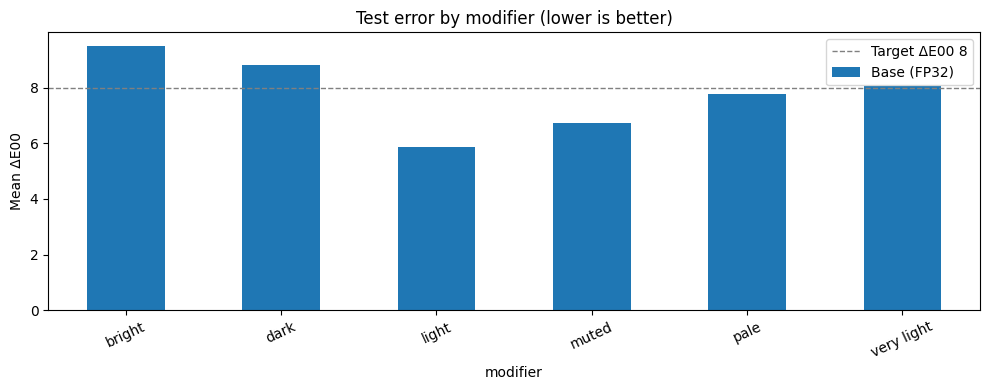

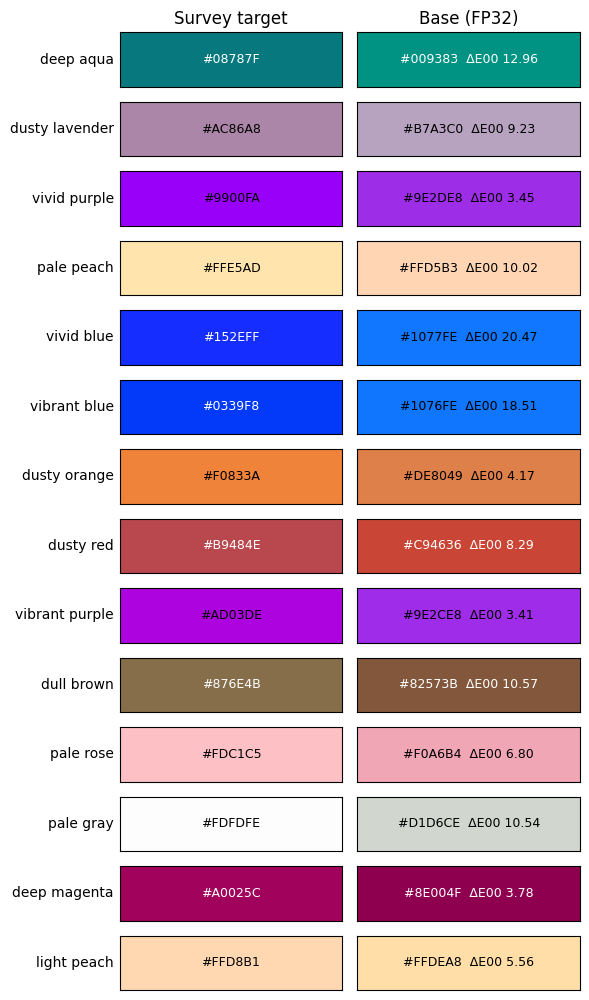

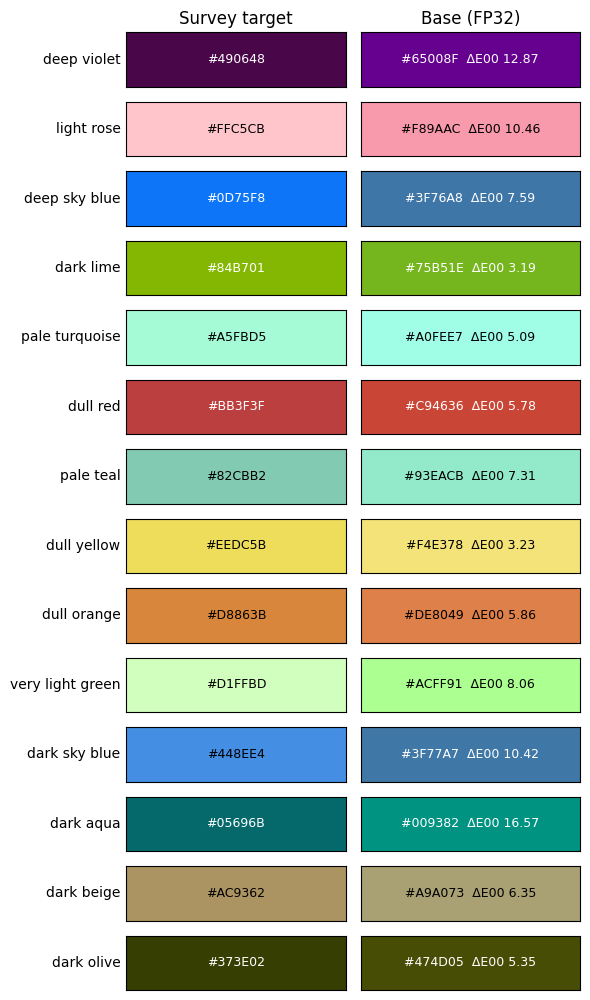

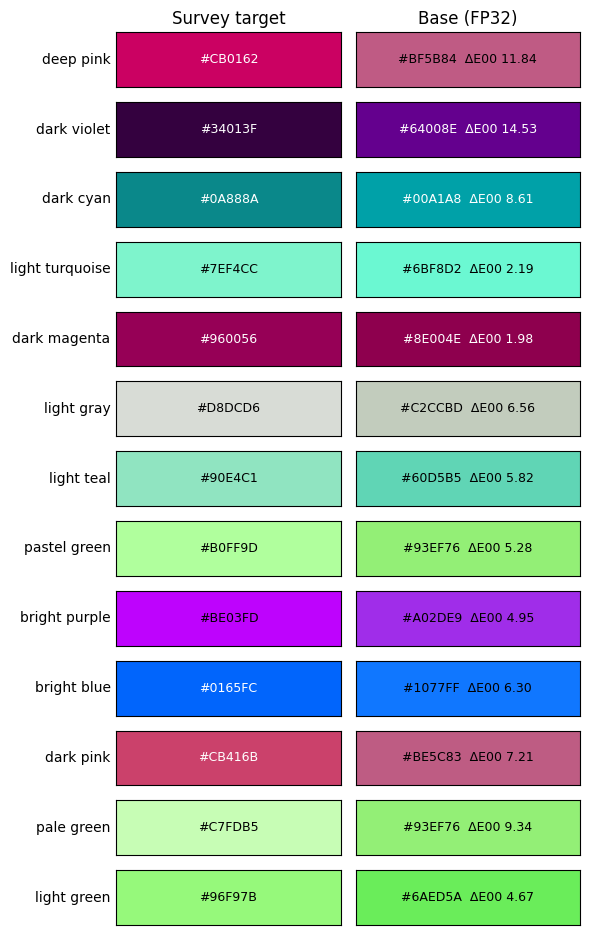

In [ ]:
def delta_e(target, prediction):
    return deltaE_ciede2000(rgb2lab(np.clip(target, 0, 1)),
                           rgb2lab(np.clip(prediction, 0, 1)))


def predict(frame, model, base_colors):
    return predict_array(model, encode_frame(frame, base_colors))


val = H["validation"]
val_pred = predict(val, validation_model, validation_bases)
print("Validation mean ΔE00:", round(float(delta_e(np.stack(val.rgb), val_pred).mean()), 3))

test = H["test"]
y_test = np.stack(test.rgb)
x_test = encode_frame(test, base_colors)
base_pred = predict_array(model, x_test)
assert base_pred.shape == (len(test), 3) and np.isfinite(base_pred).all()
assert ((base_pred >= 0) & (base_pred <= 1)).all()



def report(predictions):
    errors = pd.DataFrame({name: delta_e(y_test, rgb) for name, rgb in predictions.items()})
    display(pd.DataFrame({"mean ΔE00": errors.mean(), "median ΔE00": errors.median(),
                          "p90 ΔE00": errors.quantile(.9)}).round(3))
    by_modifier = errors.groupby(test.modifier).mean()
    by_modifier.insert(0, "n", test.groupby("modifier").size())
    display(by_modifier.round(3))
    ax = by_modifier.drop(columns="n").plot.bar(rot=25, figsize=(10, 4), ylabel="Mean ΔE00")
    ax.axhline(8, linestyle="--", color="gray", linewidth=1, label="Target ΔE00 8")
    ax.legend()
    ax.set_title("Test error by modifier (lower is better)")
    plt.tight_layout()
    plt.show()
    return errors


def show_colors(names, targets, predictions, page_size=14):
    columns = {"Survey target": targets, **predictions}
    for start in range(0, len(names), page_size):
        stop = min(start + page_size, len(names))
        fig, axes = plt.subplots(stop-start, len(columns), squeeze=False,
                                 figsize=(3*len(columns), .65*(stop-start)+1))
        for col, (label, colors) in enumerate(columns.items()):
            de = delta_e(targets, colors)
            for i, index in enumerate(range(start, stop)):
                ax, rgb = axes[i, col], np.clip(colors[index], 0, 1)
                ax.set_facecolor(rgb)
                ax.set_xticks([]); ax.set_yticks([])
                txt = to_hex(rgb).upper()
                if col: txt += f"  ΔE00 {de[index]:.2f}"
                ax.text(.5, .5, txt, ha="center", va="center", transform=ax.transAxes,
                        color="white" if rgb.mean() < .5 else "black", fontsize=9)
                if col == 0: ax.set_ylabel(names[index], rotation=0, ha="right", va="center")
            axes[0, col].set_title(label)
        fig.tight_layout()
        plt.show()
        plt.close(fig)


base_errors = report({"Base (FP32)": base_pred})
show_colors(test.name.tolist(), y_test, {"Base (FP32)": base_pred})

,name,modifier,target,prediction,ΔE00
21,dark aqua,dark,#05696b,#009382,16.569
25,dark violet,dark,#34013f,#64008e,14.533
0,deep aqua,dark,#08787f,#009383,12.961
10,deep violet,dark,#490648,#65008f,12.872
24,deep pink,dark,#cb0162,#bf5b84,11.838
5,dull brown,muted,#876e4b,#82573b,10.570
7,pale gray,pale,#fdfdfe,#d1d6ce,10.544
11,light rose,light,#ffc5cb,#f89aac,10.462
20,dark sky blue,dark,#448ee4,#3f77a7,10.416
2,pale peach,pale,#ffe5ad,#ffd5b3,10.020


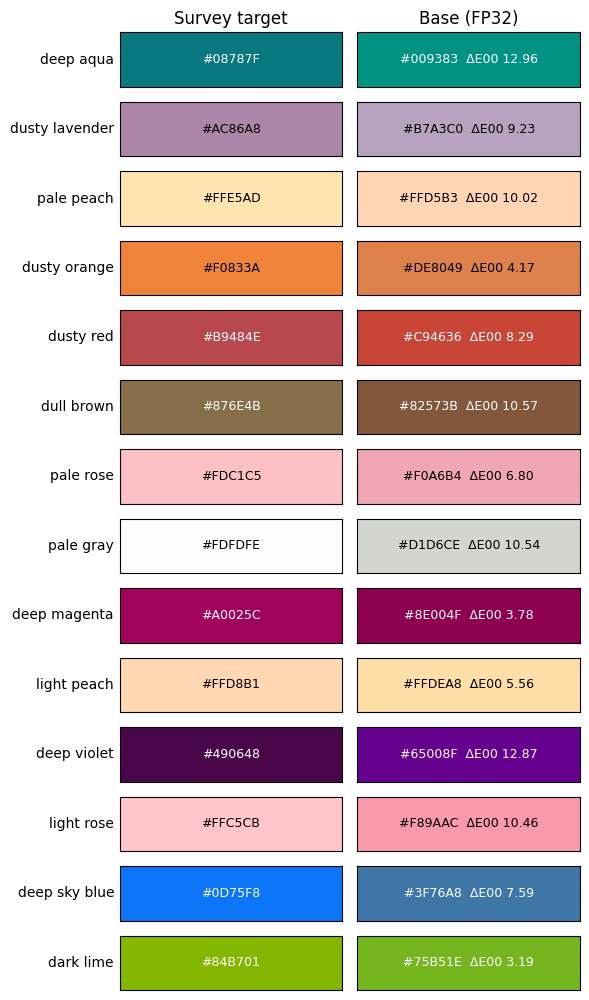

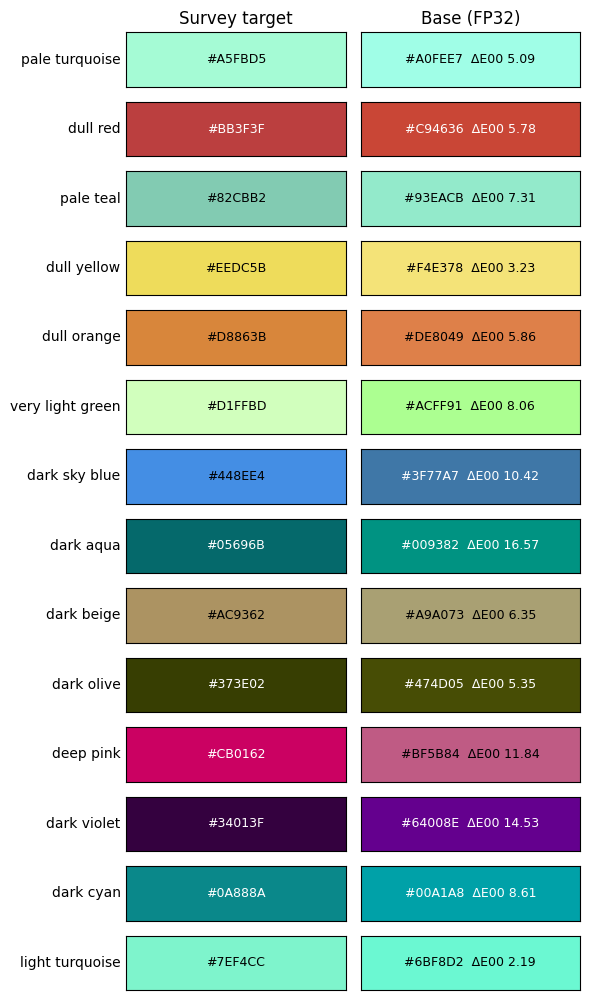

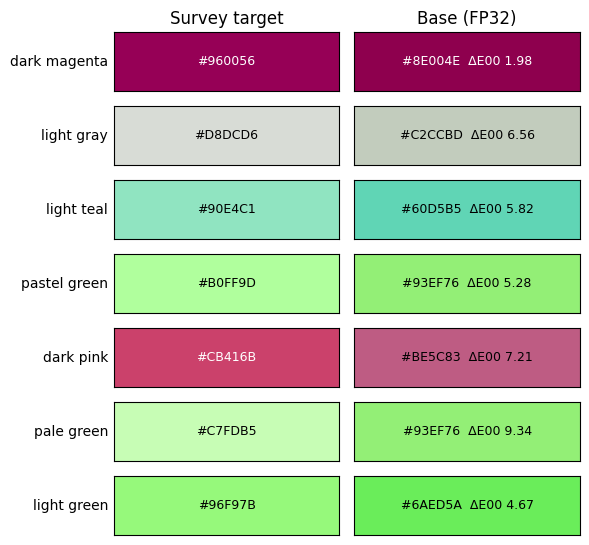

Categories at or above ΔE00 8: {'bright': 9.513999938964844, 'dark': 8.803999900817871, 'very light': 8.062000274658203}


In [ ]:
muted = test.modifier.eq("muted").to_numpy()
focus = test.modifier.isin(["dark", "light", "very light", "pale", "muted"]).to_numpy()
details = pd.DataFrame({
    "name": test.loc[focus, "name"].to_numpy(),
    "modifier": test.loc[focus, "modifier"].to_numpy(),
    "target": [to_hex(c) for c in y_test[focus]],
    "prediction": [to_hex(c) for c in base_pred[focus]],
    "ΔE00": delta_e(y_test[focus], base_pred[focus])
})
display(details.sort_values("ΔE00", ascending=False).round(3))
show_colors(test.loc[focus, "name"].tolist(), y_test[focus], {"Base (FP32)": base_pred[focus]})
modifier_means = base_errors.groupby(test.modifier).mean()["Base (FP32)"]
above_target = modifier_means[modifier_means >= 8]
if len(above_target):
    print("Categories at or above ΔE00 8:", above_target.round(3).to_dict())


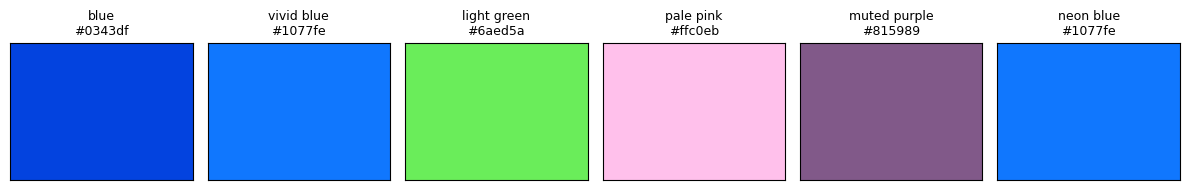

In [ ]:
examples = ["blue", "vivid blue", "light green", "pale pink", "muted purple", "neon blue"]
features = np.stack([encode_text(text, base_colors) for text in examples])
colors = predict_array(model, features)
fig, axes = plt.subplots(1, len(examples), figsize=(12, 2))
for ax, name, rgb in zip(axes, examples, colors):
    ax.set_facecolor(rgb); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(name + "\n" + to_hex(rgb), fontsize=9)
plt.tight_layout(); plt.show()

## 6. Export the trained ensemble to LiteRT (Android)

In [ ]:
import litert_torch
from ai_edge_quantizer import quantizer, recipe
from ai_edge_litert.interpreter import Interpreter
from collections import Counter
from tempfile import TemporaryDirectory

DEPLOY = OUT / "android"
DEPLOY.mkdir(exist_ok=True)
DYNAMIC_PATH = DEPLOY / "text_to_color_dynamic_int8.tflite"
ENCODER_PATH = DEPLOY / "text_to_color_encoder.json"

x_train_export = encode_frame(final_train, base_colors).astype(np.float32)
assert not set(final_train.group) & set(test.group)
assert x_train_export.shape == (len(final_train), INPUT_SIZE)
assert np.isfinite(x_train_export).all()
assert x_train_export.min() >= 0 and x_train_export.max() <= 1
assert np.all(x_train_export[:, 3:3+M].sum(1) == 1)
assert np.all(x_train_export[:, 3+M:].sum(1) == 1)

# Rebuild from the current class definitions without retraining. This also
# supports an existing kernel where model still refers to the old classes.
model = model.cpu().eval()
export_model = Ensemble([WordNet(dict(model.rgb_net.cfg)),
                         WordNet(dict(model.lab_net.cfg))]).cpu().eval()
export_model.load_state_dict(model.state_dict(), strict=True)

# Verify every valid modifier ID encodes identically to the original one_hot.
# This check is outside the graph being converted.
ids = torch.arange(M)
expected = nn.functional.one_hot(ids, M).float()
actual = (ids[:, None] == torch.arange(M)[None, :]).float()
torch.testing.assert_close(actual, expected, rtol=0, atol=0)

# Compare the reloaded model to the original trained model before export.
# Test colors are used only for parity/evaluation; no calibration is needed.
x_parity = np.concatenate([x_train_export, x_test], axis=0).astype(np.float32)
with torch.no_grad():
    parity_input = torch.from_numpy(x_parity)
    expected_rgb = model(parity_input)
    actual_rgb = export_model(parity_input)
    torch.testing.assert_close(actual_rgb, expected_rgb, rtol=1e-6, atol=1e-6)
    print("Export rewrite parity: max absolute RGB difference =",
          float((actual_rgb - expected_rgb).abs().max()))

# Fixed batch size of one for interactive Android inference.
sample_inputs = (torch.from_numpy(x_train_export[:1].copy()),)
# Inspect the actual exported graph before handing it to LiteRT.
exported_program = torch.export.export(export_model, sample_inputs)
assert not any("aten.one_hot" in str(node.target)
               for node in exported_program.graph.nodes), "Old one_hot graph detected"

W1127 10:17:59.103000 7509 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Export rewrite parity: max absolute RGB difference = 0.0


In [ ]:
def tensor_scale_zero(detail):
    scale, zero_point = detail["quantization"]
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError(f"Invalid per-tensor quantization: {detail['quantization']}")
    return float(scale), int(zero_point)


def to_litert_input(x, detail):
    dtype = np.dtype(detail["dtype"])
    x = np.asarray(x, dtype=np.float32)
    if np.issubdtype(dtype, np.floating):
        return x.astype(dtype)
    if dtype not in (np.dtype(np.int8), np.dtype(np.uint8)):
        raise TypeError(f"Unexpected input dtype: {dtype}")
    scale, zero_point = tensor_scale_zero(detail)
    limits = np.iinfo(dtype)
    return np.clip(np.rint(x / scale) + zero_point, limits.min, limits.max).astype(dtype)


def from_litert_output(y, detail):
    dtype = np.dtype(detail["dtype"])
    if np.issubdtype(dtype, np.floating):
        return np.asarray(y, dtype=np.float32)
    if dtype not in (np.dtype(np.int8), np.dtype(np.uint8)):
        raise TypeError(f"Unexpected output dtype: {dtype}")
    scale, zero_point = tensor_scale_zero(detail)
    return (np.asarray(y, dtype=np.float32) - zero_point) * scale


def open_litert(path):
    interpreter = Interpreter(model_path=str(path), num_threads=1)
    interpreter.allocate_tensors()
    assert len(interpreter.get_input_details()) == len(interpreter.get_output_details()) == 1
    assert tuple(interpreter.get_input_details()[0]["shape"]) == (1, INPUT_SIZE)
    assert tuple(interpreter.get_output_details()[0]["shape"]) == (1, 3)
    return interpreter


def infer_litert(interpreter, features):
    in_detail = interpreter.get_input_details()[0]
    out_detail = interpreter.get_output_details()[0]
    outputs = []
    for x in np.asarray(features, dtype=np.float32):
        interpreter.set_tensor(in_detail["index"], to_litert_input(x[None, :], in_detail))
        interpreter.invoke()
        outputs.append(from_litert_output(interpreter.get_tensor(out_detail["index"]), out_detail)[0])
    result = np.stack(outputs)
    assert result.shape == (len(features), 3) and np.isfinite(result).all()
    return result


# Basic signed INT8 round-trip test; use tensor-specific scale and zero point.
probe_detail = {"dtype": np.int8, "quantization": (1 / 255, -128)}
probe_rgb = np.array([[0., .5, 1.]], dtype=np.float32)
probe_q = to_litert_input(probe_rgb, probe_detail)
assert probe_q.dtype == np.int8
np.testing.assert_allclose(from_litert_output(probe_q, probe_detail), probe_rgb, atol=1/255)

In [ ]:
# FP32 is a temporary conversion intermediate, not a deployment asset.
with TemporaryDirectory(prefix="text_to_color_") as tmp:
    fp32_path = Path(tmp) / "text_to_color_fp32.tflite"
    edge_model = litert_torch.convert(export_model, sample_inputs)
    edge_model.export(str(fp32_path))
    fp32_runner = open_litert(fp32_path)
    litert_fp32_pred = infer_litert(fp32_runner, x_test)
    np.testing.assert_allclose(litert_fp32_pred, base_pred, atol=1e-4, rtol=1e-4)
    print("FP32 conversion parity: max absolute RGB difference =",
          float(np.max(np.abs(litert_fp32_pred - base_pred))))
    del fp32_runner

    dynamic_q = quantizer.Quantizer(str(fp32_path))
    dynamic_q.load_quantization_recipe(recipe.dynamic_wi8_afp32())
    dynamic_q.quantize().export_model(str(DYNAMIC_PATH), overwrite=True)
    del dynamic_q

print(f"Exported {DYNAMIC_PATH} ({DYNAMIC_PATH.stat().st_size:,} bytes)")
paths = {"LiteRT dynamic INT8": DYNAMIC_PATH}

(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


(00:02) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:01)

(00:02) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:02)

... (20 outputs left out)

(00:00) [ DONE] Write Model to /tmp/text_to_color_4wk6g3ts/text_to_color_fp32.tflite (+00:00)

FP32 conversion parity: max absolute RGB difference = 1.395791741742869e-06


Applying Transformations to tensors:: 100%|██████████| 435/435 [00:00<00:00, 140585.78it/s]

Model name: /tmp/text_to_color_4wk6g3ts/text_to_color_fp32.tflite
Original model size: 75.15 KiB
Quantized model size: 71.36 KiB
Quantization Ratio: 0.95 (1.1x smaller)
Total time: 96.40 ms
Exported color_v33_results/android/text_to_color_dynamic_int8.tflite (73,072 bytes)


In [ ]:
def io_metadata(detail):
    scale, zero_point = detail["quantization"]
    return {"name": detail["name"], "shape": detail["shape"].tolist(),
            "dtype": np.dtype(detail["dtype"]).name,
            "scale": float(scale), "zero_point": int(zero_point)}


def audit_litert(path, interpreter):
    tensors = interpreter.get_tensor_details()
    counts = Counter(np.dtype(t["dtype"]).name for t in tensors)
    floats = [t["name"] for t in tensors if np.issubdtype(t["dtype"], np.floating)]
    quantized_int8 = [t for t in tensors if t["dtype"] == np.int8
                      and len(t["quantization_parameters"]["scales"]) > 0]
    in_meta = io_metadata(interpreter.get_input_details()[0])
    out_meta = io_metadata(interpreter.get_output_details()[0])
    # Conservative tensor-level check; not proof of accelerator compatibility.
    integer_only_candidate = (not floats and bool(quantized_int8)
                              and in_meta["dtype"] == out_meta["dtype"] == "int8")
    return {"file": path.name, "bytes": path.stat().st_size,
            "input": in_meta, "output": out_meta, "tensor_dtypes": dict(counts),
            "quantized_int8_tensors": len(quantized_int8), "float_tensors": floats,
            "integer_only_candidate": integer_only_candidate}


runners = {name: open_litert(path) for name, path in paths.items()}
audits = {name: audit_litert(paths[name], runner) for name, runner in runners.items()}
summary = []
for name, audit in audits.items():
    summary.append({"model": name, "KiB": audit["bytes"] / 1024,
                    "input": audit["input"]["dtype"], "output": audit["output"]["dtype"],
                    "INT8 quantized tensors": audit["quantized_int8_tensors"],
                    "float tensors": len(audit["float_tensors"]),
                    "integer-only candidate": audit["integer_only_candidate"]})
    if "INT8" in name:
        assert audit["quantized_int8_tensors"] > 0, f"No quantized INT8 tensors: {name}"
display(pd.DataFrame(summary).set_index("model").round(3))
# Verify the Android float interface before writing the encoder metadata.
assert audits["LiteRT dynamic INT8"]["input"]["dtype"] == "float32"
assert audits["LiteRT dynamic INT8"]["output"]["dtype"] == "float32"

,KiB,input,output,INT8 quantized tensors,float tensors,integer-only candidate
model,,,,,,
LiteRT dynamic INT8,71.359,float32,float32,4,370,False


## 7. Color showcase and ΔE00 after LiteRT export

Compare real LiteRT dynamic INT8 inference against the held-out XKCD survey colors and the original PyTorch FP32 model using CIEDE2000 (ΔE00; lower is better). The temporary LiteRT FP32 predictions are used in memory to measure quantization drift independently of conversion error. Tables and swatches are displayed in the notebook only; no extra report files are needed for Android.

,mean ΔE00,median ΔE00,p90 ΔE00
PyTorch FP32,7.931,6.803,12.961
LiteRT dynamic INT8,7.934,6.818,12.979


,n,PyTorch FP32,LiteRT dynamic INT8
modifier,,,
bright,6,9.514,9.522
dark,14,8.804,8.808
light,6,5.878,5.877
muted,7,6.732,6.730
pale,7,7.770,7.775
very light,1,8.062,8.061


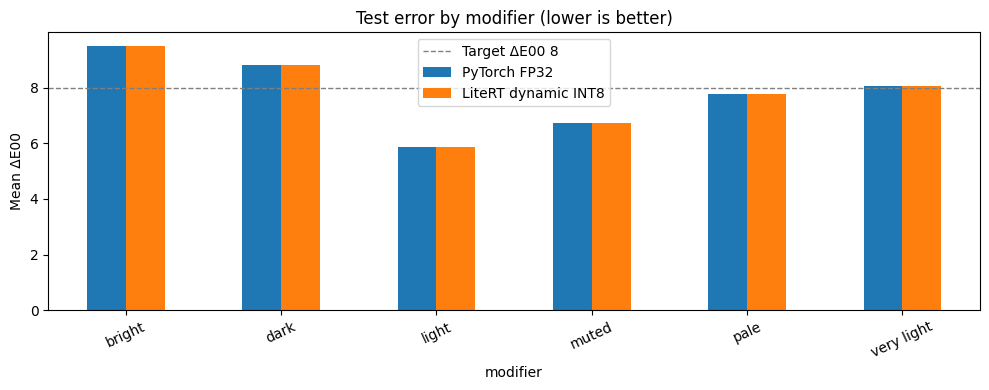

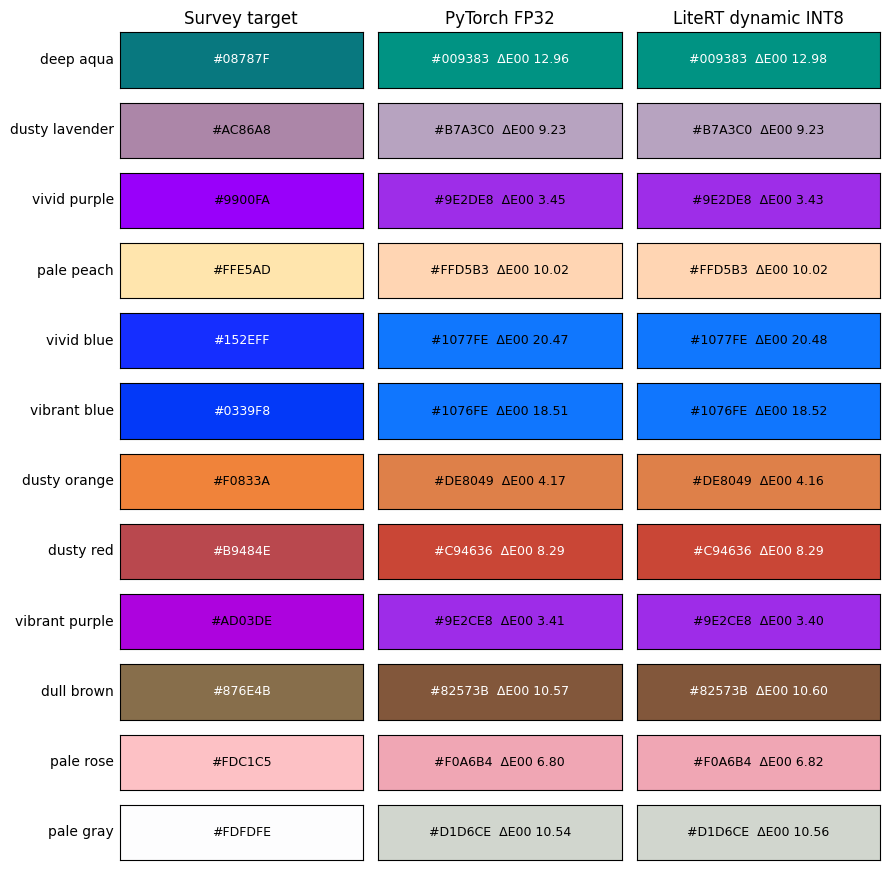

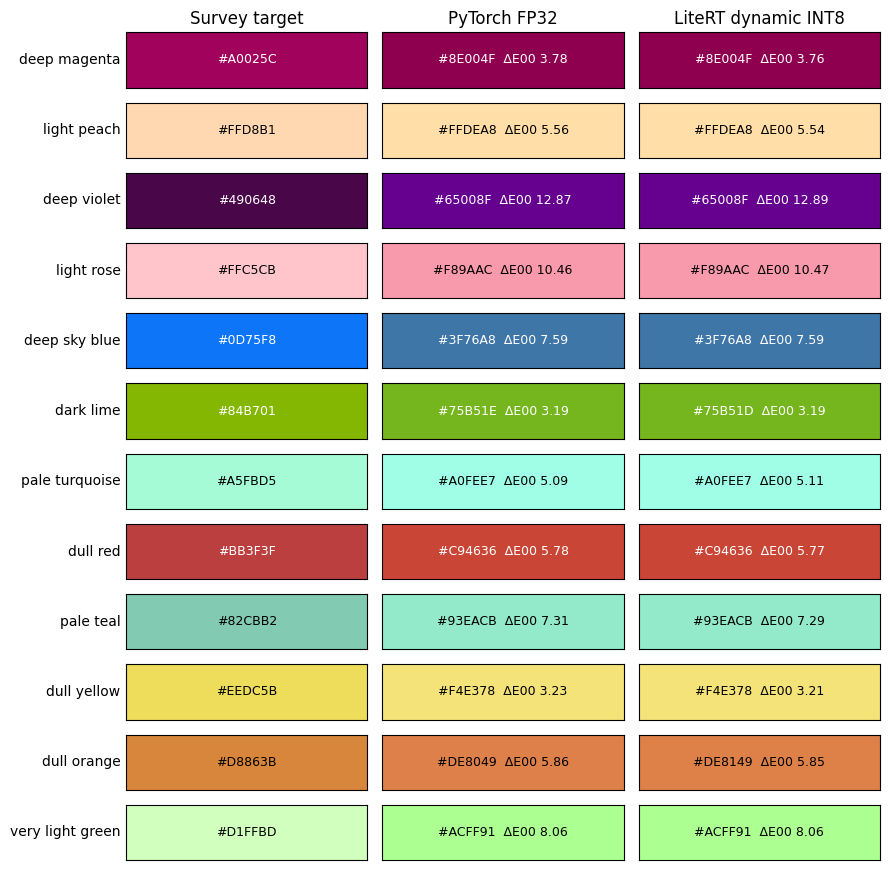

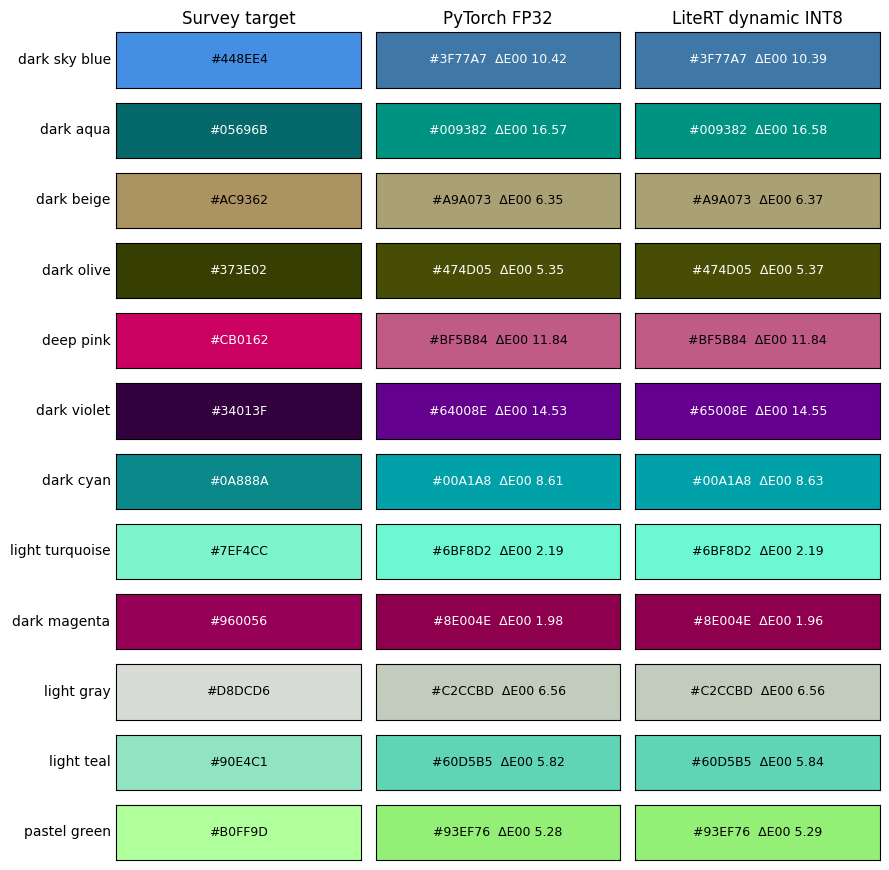

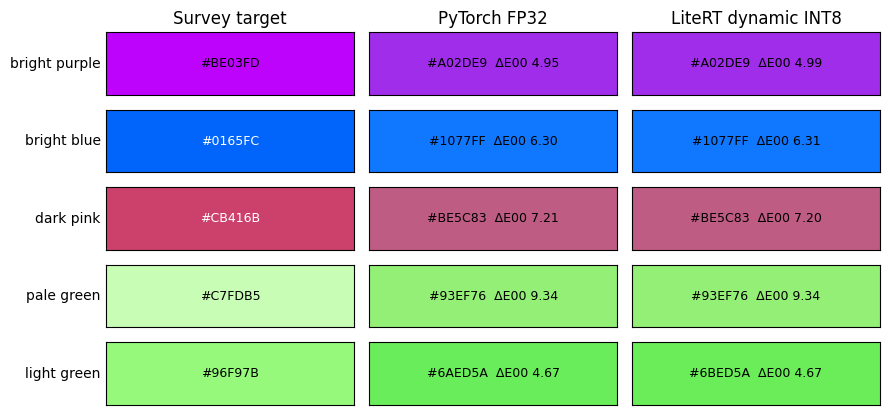

,mean survey ΔE00,change in mean survey ΔE00,mean quantization ΔE00,p90 quantization ΔE00,max quantization ΔE00
model,,,,,
LiteRT dynamic INT8,7.934,0.003,0.021,0.037,0.045


,name,modifier,survey_hex,PyTorch FP32 hex,PyTorch FP32 survey ΔE00,LiteRT dynamic INT8 hex,LiteRT dynamic INT8 survey ΔE00,LiteRT dynamic INT8 quantization ΔE00
4,vivid blue,bright,#152EFF,#1077FE,20.469999,#1077FE,20.483999,0.014
5,vibrant blue,bright,#0339F8,#1076FE,18.504999,#1076FE,18.518999,0.014
25,dark aqua,dark,#05696B,#009382,16.569000,#009382,16.583000,0.020
29,dark violet,dark,#34013F,#64008E,14.533000,#65008E,14.552000,0.022
0,deep aqua,dark,#08787F,#009383,12.961000,#009383,12.979000,0.020
14,deep violet,dark,#490648,#65008F,12.872000,#65008F,12.887000,0.020
28,deep pink,dark,#CB0162,#BF5B84,11.838000,#BF5B84,11.842000,0.024
9,dull brown,muted,#876E4B,#82573B,10.570000,#82573B,10.597000,0.037
11,pale gray,pale,#FDFDFE,#D1D6CE,10.544000,#D1D6CE,10.555000,0.028
15,light rose,light,#FFC5CB,#F89AAC,10.462000,#F89AAC,10.468000,0.008


In [ ]:
predictions = {"PyTorch FP32": base_pred}
for name, runner in runners.items():
    predictions[name] = infer_litert(runner, x_test)

# Overall and modifier-wise survey error, using the existing evaluation helper.
export_errors = report(predictions)
show_colors(test.name.tolist(), y_test, predictions, page_size=12)

# Separate error from quantization versus the reference LiteRT FP32 graph.
quant_summary = []
reference = litert_fp32_pred
for name in paths:
    if name == "LiteRT FP32":
        continue
    drift = delta_e(reference, predictions[name])
    survey = export_errors[name]
    quant_summary.append({"model": name,
                          "mean survey ΔE00": survey.mean(),
                          "change in mean survey ΔE00": survey.mean()-delta_e(y_test, reference).mean(),
                          "mean quantization ΔE00": drift.mean(),
                          "p90 quantization ΔE00": np.quantile(drift, .9),
                          "max quantization ΔE00": drift.max()})
quant_summary = pd.DataFrame(quant_summary).set_index("model")
display(quant_summary.round(3))

comparison = pd.DataFrame({"name": test.name, "modifier": test.modifier,
                           "survey_hex": [to_hex(c).upper() for c in y_test]})
for name, rgb in predictions.items():
    comparison[name + " hex"] = [to_hex(np.clip(c, 0, 1)).upper() for c in rgb]
    comparison[name + " survey ΔE00"] = export_errors[name]
    if "INT8" in name:
        comparison[name + " quantization ΔE00"] = delta_e(reference, rgb)
display(comparison.sort_values("LiteRT dynamic INT8 survey ΔE00", ascending=False).round(3))

## 8. Android assets

Only two deployment files are required: `text_to_color_dynamic_int8.tflite` (the trained model) and `text_to_color_encoder.json` (the ordered feature encoder, RGB anchors, aliases and model I/O metadata). No FP32 model, calibration data, test vectors or evaluation reports need to be shipped.

Encoding contract: normalize with ASCII `[a-z0-9]+` tokens, replace `grey` with `gray`, strip a leading article and trailing `color`/`shade`, then try bases longest-first. Reject unsupported modifiers and modified `black`/`white`. Features are `[base RGB, modifier one-hot, word one-hot]`, with exactly the exported ordering. Input shape is `[1, INPUT_SIZE]`; output is `[1, 3]`. The dynamic model uses float32 input and output in the range `[0, 1]` for RGB channels.

In [ ]:
metadata = {
    "schema_version": 1,
    "input_size": INPUT_SIZE,
    "base_order": BASE_ORDER,
    "base_colors": {b: base_colors[b].tolist() for b in BASE_ORDER},
    "modifiers": MODIFIERS,
    "words": WORDS,
    "forms": ALL_FORMS,
    "output_color_space": "sRGB",
    "output_range": [0, 1],
    "models": {name: {"file": audit["file"], "input": audit["input"],
                      "output": audit["output"]} for name, audit in audits.items()}
}
ENCODER_PATH.write_text(json.dumps(metadata, indent=2))

print("Android deployment files:")
for path in (DYNAMIC_PATH, ENCODER_PATH):
    print(f"{path.name:40s} {path.stat().st_size:>10,} bytes")

Android deployment files:
text_to_color_dynamic_int8.tflite            73,072 bytes
text_to_color_encoder.json                    5,322 bytes


### Download the two Android deployment files
Run the following cell in Colab after export. If the browser blocks the second download, allow multiple downloads or download the files from the printed paths in the Colab file browser.

In [ ]:
for path in (DYNAMIC_PATH, ENCODER_PATH):
    assert path.is_file() and path.stat().st_size > 0, f"Missing or empty: {path}"
try:
    from google.colab import files
except ImportError:
    for path in (DYNAMIC_PATH, ENCODER_PATH):
        print(path.resolve())
else:
    files.download(str(DYNAMIC_PATH))
    files.download(str(ENCODER_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>